# Scent Duration Prediction System for IFF

This notebook builds an end-to-end machine learning workflow for predicting fragrance longevity from formulation, physicochemical, categorical, and ingredient features.

**Business objective:** help perfumers and product teams estimate scent duration, identify the strongest longevity drivers, and recommend ingredient combinations for a target duration.

**Workflow covered**

1. Data loading and exploratory analysis
2. Feature engineering, ingredient parsing, and encoding
3. Regression modeling for `ScentDuration_Hours`
4. Classification modeling for `LongevityCategory`
5. Hyperparameter tuning
6. Feature importance and SHAP interpretability
7. Ingredient impact analysis and ingredient combination recommendations
8. Artifact export for the Streamlit app and summary report

In [1]:
# Core imports and project configuration
from __future__ import annotations

import itertools
import json
import math
import re
import warnings
from collections import Counter
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from IPython.display import HTML, display
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingRegressor, RandomForestClassifier, RandomForestRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import KFold, RandomizedSearchCV, StratifiedKFold, cross_validate, train_test_split
from sklearn.multiclass import OneVsRestClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import LabelEncoder, MultiLabelBinarizer, StandardScaler
from sklearn.svm import SVR

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook", palette="Set2")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 180
plt.rcParams["axes.titleweight"] = "bold"

RANDOM_STATE = 42
DATA_PATH = Path("ProjectB_Scent_Duration_Dataset.xlsx")
OUTPUT_DIR = Path("outputs")
FIG_DIR = OUTPUT_DIR / "figures"
MODEL_DIR = Path("models")
REPORT_DIR = Path("reports")

for directory in [OUTPUT_DIR, FIG_DIR, MODEL_DIR, REPORT_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print(f"Working directory: {Path.cwd()}")
print(f"Dataset expected at: {DATA_PATH.resolve()}")

Working directory: C:\Users\shaik\OneDrive\Documents\Scent_Duration
Dataset expected at: C:\Users\shaik\OneDrive\Documents\Scent_Duration\ProjectB_Scent_Duration_Dataset.xlsx


## 1. Data Loading and Exploration

The dataset is loaded from Excel using pandas. This section performs structural checks, summarizes missingness, examines numerical distributions, and visualizes the relationship between formulation features and scent duration.

In [2]:
required_columns = [
    "FragranceID",
    "FragranceFamily",
    "ApplicationType",
    "Concentration_Pct",
    "TopNotes_Pct",
    "MiddleNotes_Pct",
    "BaseNotes_Pct",
    "Ingredients",
    "NumIngredients",
    "AvgMolecularWeight",
    "VolatilityScore",
    "LogP",
    "VaporPressure_Pa",
    "BoilingPoint_C",
    "ScentDuration_Hours",
    "LongevityCategory",
]

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH.resolve()}. "
        "Place ProjectB_Scent_Duration_Dataset.xlsx in this project folder and rerun the notebook."
    )

df = pd.read_excel(DATA_PATH)
missing_required = sorted(set(required_columns) - set(df.columns))
if missing_required:
    raise ValueError(f"Missing required columns: {missing_required}")

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (500, 16)


,FragranceID,FragranceFamily,ApplicationType,Concentration_Pct,TopNotes_Pct,MiddleNotes_Pct,BaseNotes_Pct,Ingredients,NumIngredients,AvgMolecularWeight,VolatilityScore,LogP,VaporPressure_Pa,BoilingPoint_C,ScentDuration_Hours,LongevityCategory
0,FRAG0001,Chypre,Eau de Toilette,5.9,36.4,33.7,29.9,"Grapefruit, Ylang-ylang, Amber",3,216,0.429,3.39,40,262,3.6,Medium
1,FRAG0002,Chypre,Eau de Parfum,17.9,36.1,35.0,28.9,"Grapefruit, Gardenia, Benzoin, Oakmoss",4,182,0.523,3.97,76,241,20.4,Very Long
2,FRAG0003,Gourmand,Body Lotion,1.8,23.9,35.0,41.1,"Lavender, Grapefruit, Orange, Ylang-ylang, Lil...",8,189,0.445,3.31,18,276,0.8,Short
3,FRAG0004,Woody,Eau de Cologne,4.4,36.2,22.4,41.4,"Mandarin, Geranium, Jasmine, Cedar, Oakmoss, P...",6,189,0.458,3.22,20,274,1.3,Short
4,FRAG0005,Gourmand,Candle,5.1,26.5,20.7,52.8,"Orange, Bergamot, Lily, Freesia, Tuberose, Musk",6,185,0.276,3.85,9,271,5.7,Medium


In [3]:
print("Data types")
display(df.dtypes.to_frame("dtype"))

print("Missing values")
missing_summary = (
    df.isna()
    .sum()
    .to_frame("missing_count")
    .assign(missing_pct=lambda x: (x["missing_count"] / len(df) * 100).round(2))
    .sort_values("missing_count", ascending=False)
)
display(missing_summary)

print("Basic numeric statistics")
display(df.describe(include=[np.number]).T)

print("Categorical statistics")
display(df.describe(include=["object"]).T)

Data types


,dtype
FragranceID,object
FragranceFamily,object
ApplicationType,object
Concentration_Pct,float64
TopNotes_Pct,float64
MiddleNotes_Pct,float64
BaseNotes_Pct,float64
Ingredients,object
NumIngredients,int64
AvgMolecularWeight,int64


Missing values


,missing_count,missing_pct
FragranceID,0,0.0
FragranceFamily,0,0.0
ApplicationType,0,0.0
Concentration_Pct,0,0.0
TopNotes_Pct,0,0.0
MiddleNotes_Pct,0,0.0
BaseNotes_Pct,0,0.0
Ingredients,0,0.0
NumIngredients,0,0.0
AvgMolecularWeight,0,0.0


Basic numeric statistics


,count,mean,std,min,25%,50%,75%,max
Concentration_Pct,500.0,10.064800,6.172130,1.000,3.900,9.400,16.20000,20.000
TopNotes_Pct,500.0,30.134600,5.764436,20.000,25.300,29.800,35.30000,39.900
MiddleNotes_Pct,500.0,29.934800,5.681834,20.000,24.975,30.000,34.52500,40.000
BaseNotes_Pct,500.0,39.929400,8.276223,20.900,33.900,39.600,46.32500,58.800
NumIngredients,500.0,5.976000,1.451771,3.000,5.000,6.000,7.00000,9.000
AvgMolecularWeight,500.0,189.316000,22.405270,128.000,174.000,189.000,203.00000,286.000
VolatilityScore,500.0,0.457316,0.068987,0.276,0.411,0.456,0.49725,0.727
LogP,500.0,3.666840,0.541558,1.750,3.330,3.685,4.02000,5.380
VaporPressure_Pa,500.0,22.756000,12.638985,5.000,14.000,19.500,29.00000,76.000
BoilingPoint_C,500.0,266.260000,19.357837,212.000,253.000,266.000,280.00000,320.000


Categorical statistics


,count,unique,top,freq
FragranceID,500,500,FRAG0001,1
FragranceFamily,500,6,Gourmand,92
ApplicationType,500,5,Eau de Parfum,159
Ingredients,500,500,"Grapefruit, Ylang-ylang, Amber",1
LongevityCategory,500,4,Very Long,177


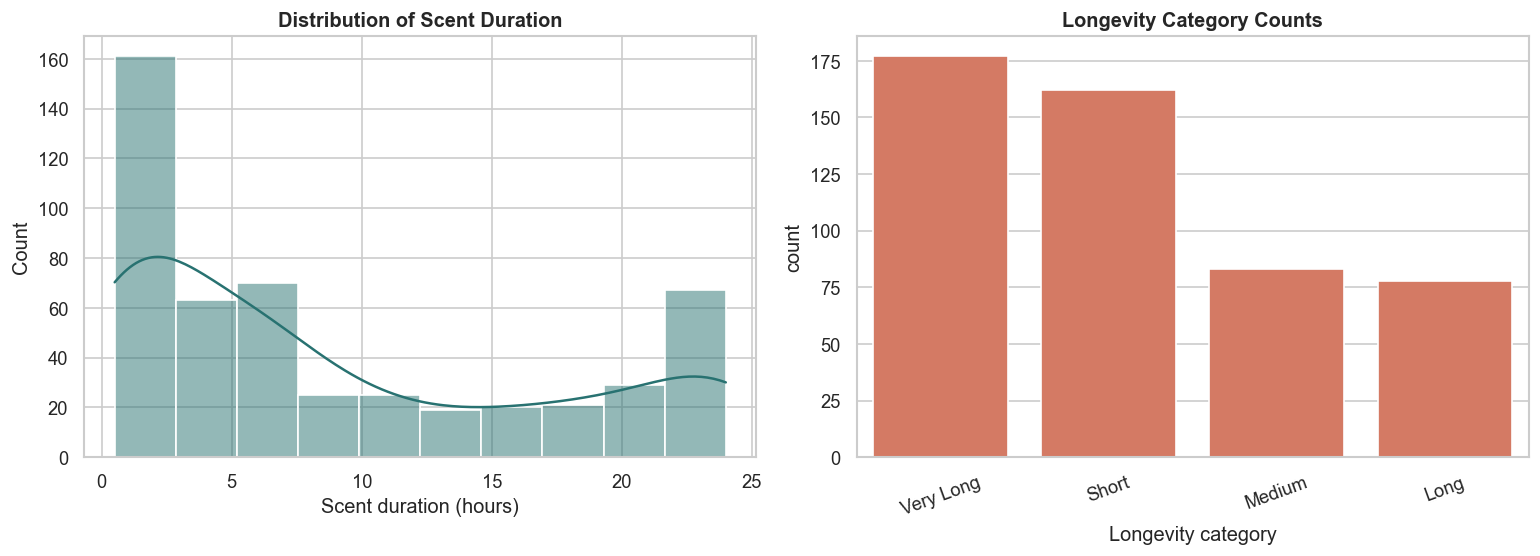

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.histplot(df["ScentDuration_Hours"], kde=True, ax=axes[0], color="#287271")
axes[0].set_title("Distribution of Scent Duration")
axes[0].set_xlabel("Scent duration (hours)")

order = df["LongevityCategory"].value_counts().index
sns.countplot(data=df, x="LongevityCategory", order=order, ax=axes[1], color="#E76F51")
axes[1].set_title("Longevity Category Counts")
axes[1].set_xlabel("Longevity category")
axes[1].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.savefig(FIG_DIR / "duration_and_category_distributions.png", bbox_inches="tight")
plt.show()

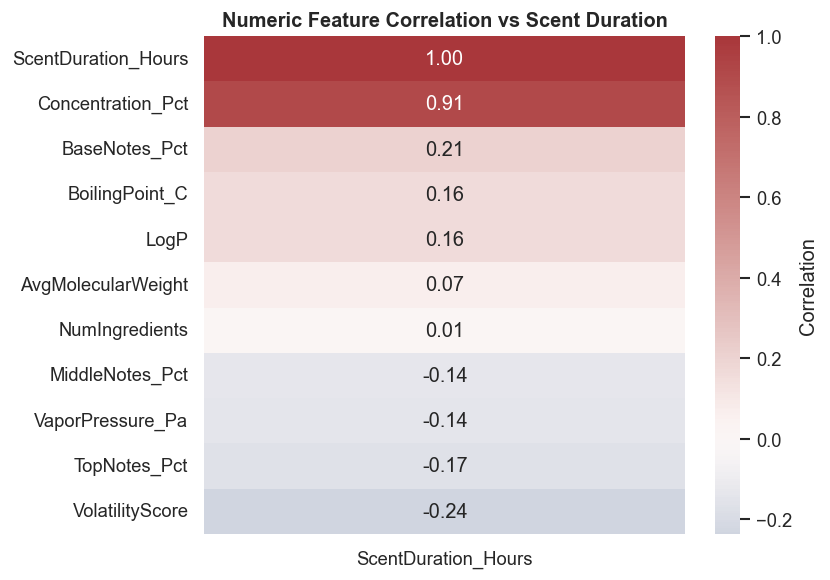

,ScentDuration_Hours
ScentDuration_Hours,1.000000
Concentration_Pct,0.911525
BaseNotes_Pct,0.210090
BoilingPoint_C,0.163018
LogP,0.155343
AvgMolecularWeight,0.070436
NumIngredients,0.006473
MiddleNotes_Pct,-0.138531
VaporPressure_Pa,-0.143595
TopNotes_Pct,-0.165668


In [5]:
numeric_cols = df.select_dtypes(include=[np.number]).columns.tolist()
corr = df[numeric_cols].corr(numeric_only=True)
target_corr = corr[["ScentDuration_Hours"]].sort_values("ScentDuration_Hours", ascending=False)

plt.figure(figsize=(7, max(5, 0.35 * len(target_corr))))
sns.heatmap(target_corr, annot=True, cmap="vlag", center=0, fmt=".2f", cbar_kws={"label": "Correlation"})
plt.title("Numeric Feature Correlation vs Scent Duration")
plt.tight_layout()
plt.savefig(FIG_DIR / "numeric_correlation_vs_duration.png", bbox_inches="tight")
plt.show()

display(target_corr)

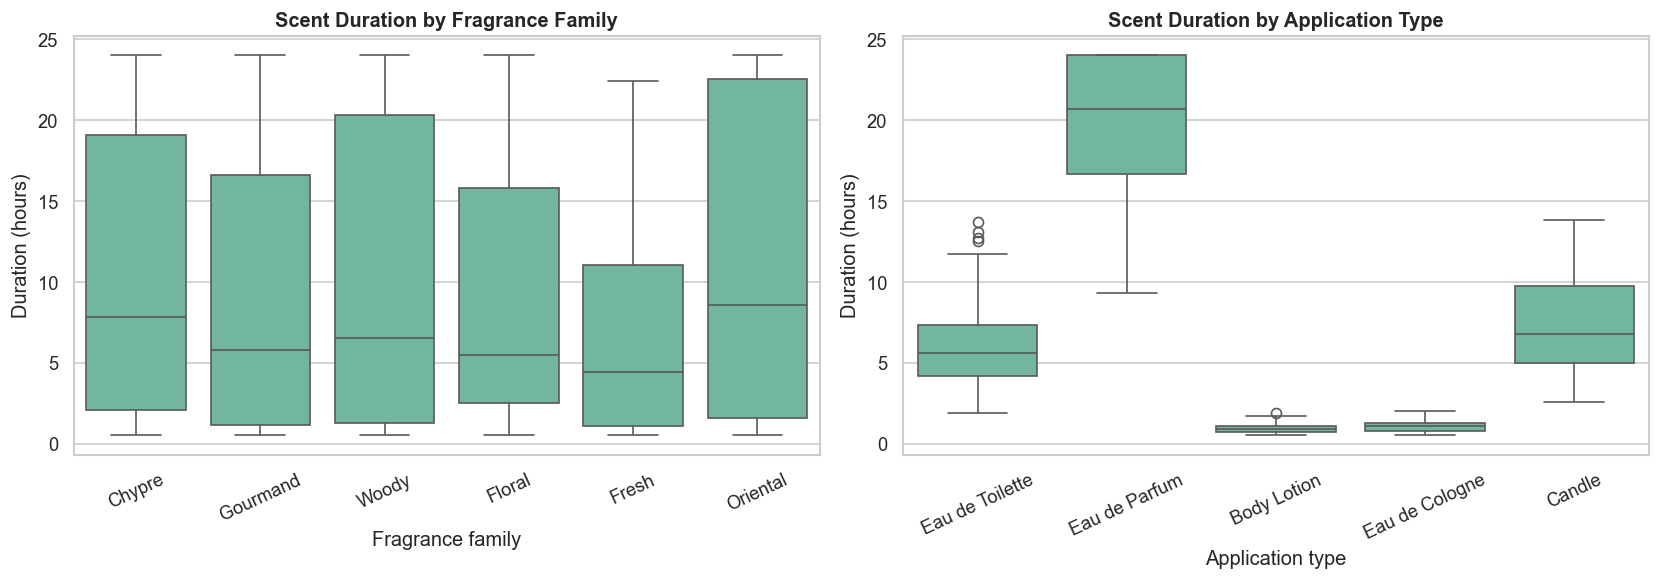

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x="FragranceFamily", y="ScentDuration_Hours", ax=axes[0])
axes[0].set_title("Scent Duration by Fragrance Family")
axes[0].set_xlabel("Fragrance family")
axes[0].set_ylabel("Duration (hours)")
axes[0].tick_params(axis="x", rotation=25)

sns.boxplot(data=df, x="ApplicationType", y="ScentDuration_Hours", ax=axes[1])
axes[1].set_title("Scent Duration by Application Type")
axes[1].set_xlabel("Application type")
axes[1].set_ylabel("Duration (hours)")
axes[1].tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(FIG_DIR / "duration_boxplots_by_category.png", bbox_inches="tight")
plt.show()

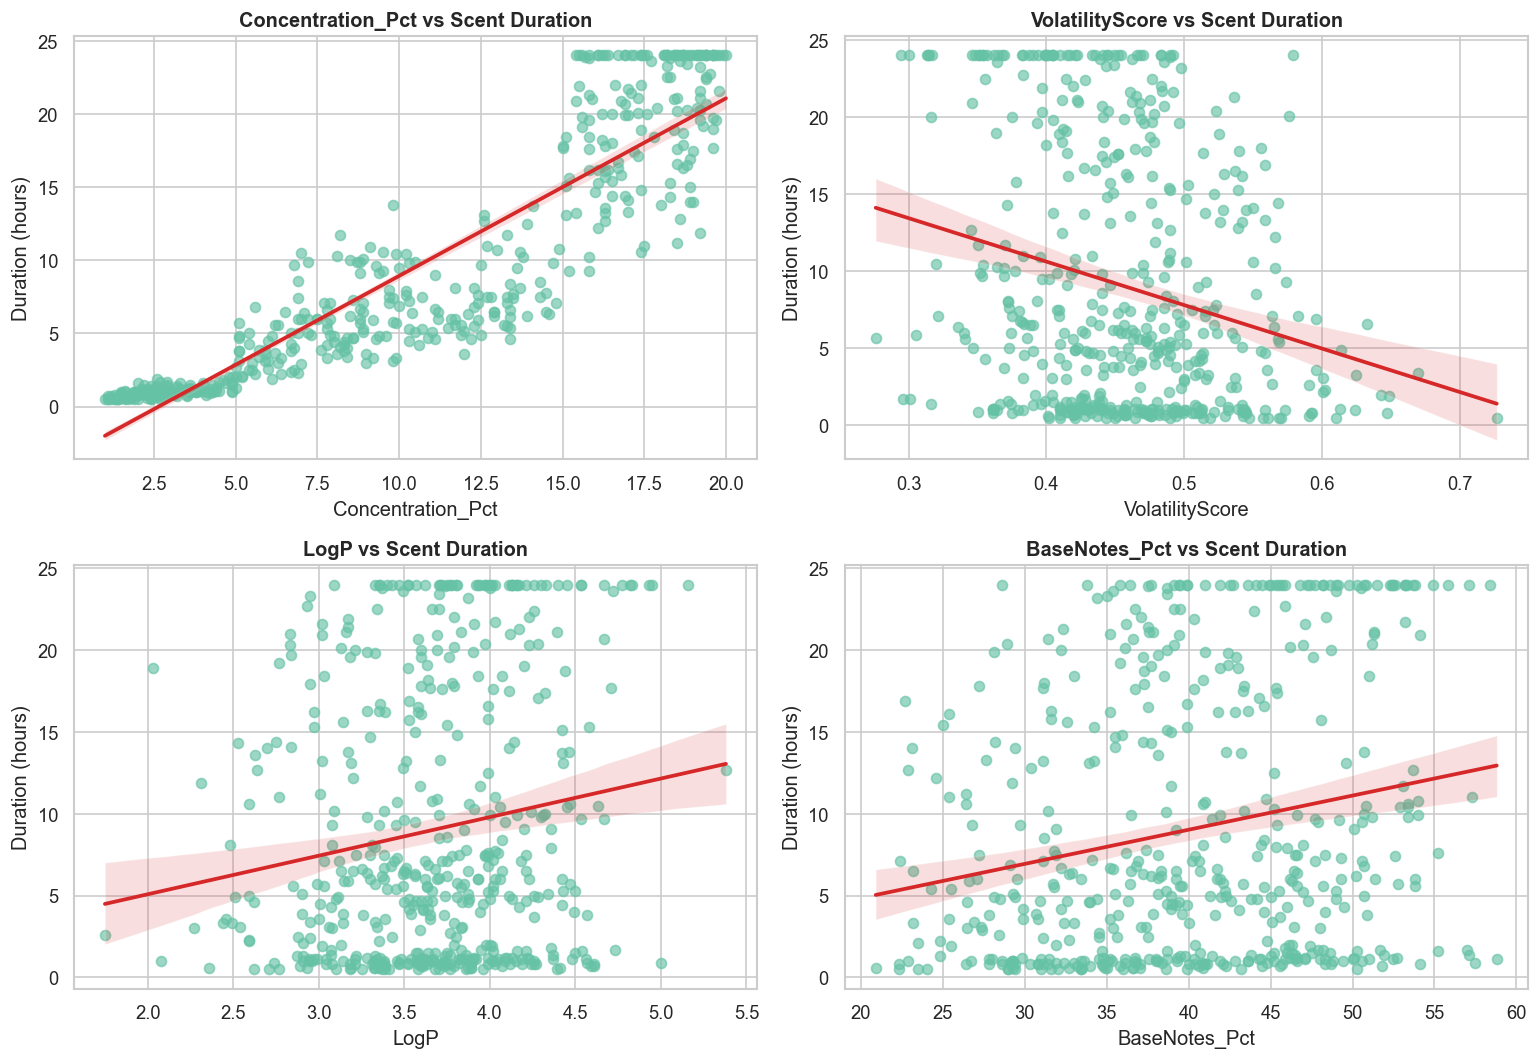

In [7]:
scatter_features = ["Concentration_Pct", "VolatilityScore", "LogP", "BaseNotes_Pct"]
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, feature in zip(axes.ravel(), scatter_features):
    sns.regplot(data=df, x=feature, y="ScentDuration_Hours", ax=ax, scatter_kws={"alpha": 0.65}, line_kws={"color": "#D62828"})
    ax.set_title(f"{feature} vs Scent Duration")
    ax.set_ylabel("Duration (hours)")

plt.tight_layout()
plt.savefig(FIG_DIR / "key_scatter_relationships.png", bbox_inches="tight")
plt.show()

,ingredient_list,appearances,avg_scent_duration,std_scent_duration
0,violet,112,8.873214,8.243457
1,ylang ylang,110,9.259091,8.327090
2,freesia,109,9.505505,7.936680
3,geranium,109,8.955963,8.166411
4,basil,108,9.390741,8.243168
5,patchouli,108,9.250000,8.759097
6,vetiver,108,9.022222,8.078567
7,lemon,106,9.501887,7.881346
8,cedar,105,8.356190,8.105671
9,lily,104,10.074038,8.566666


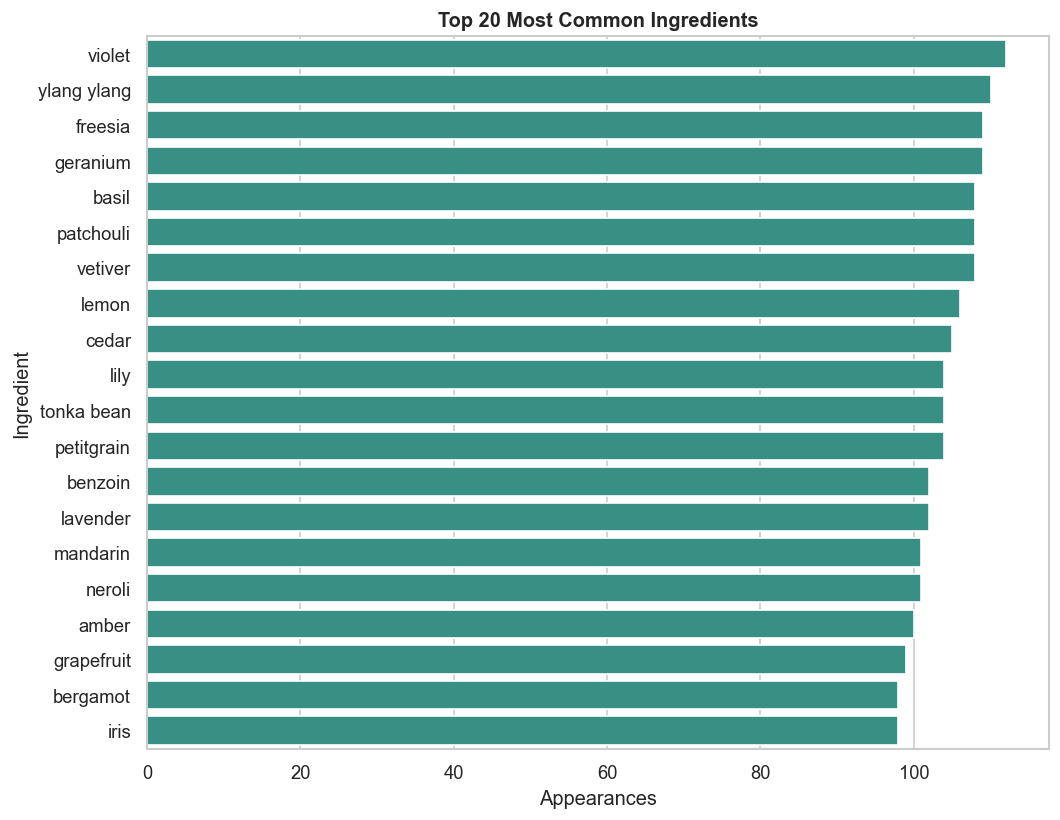

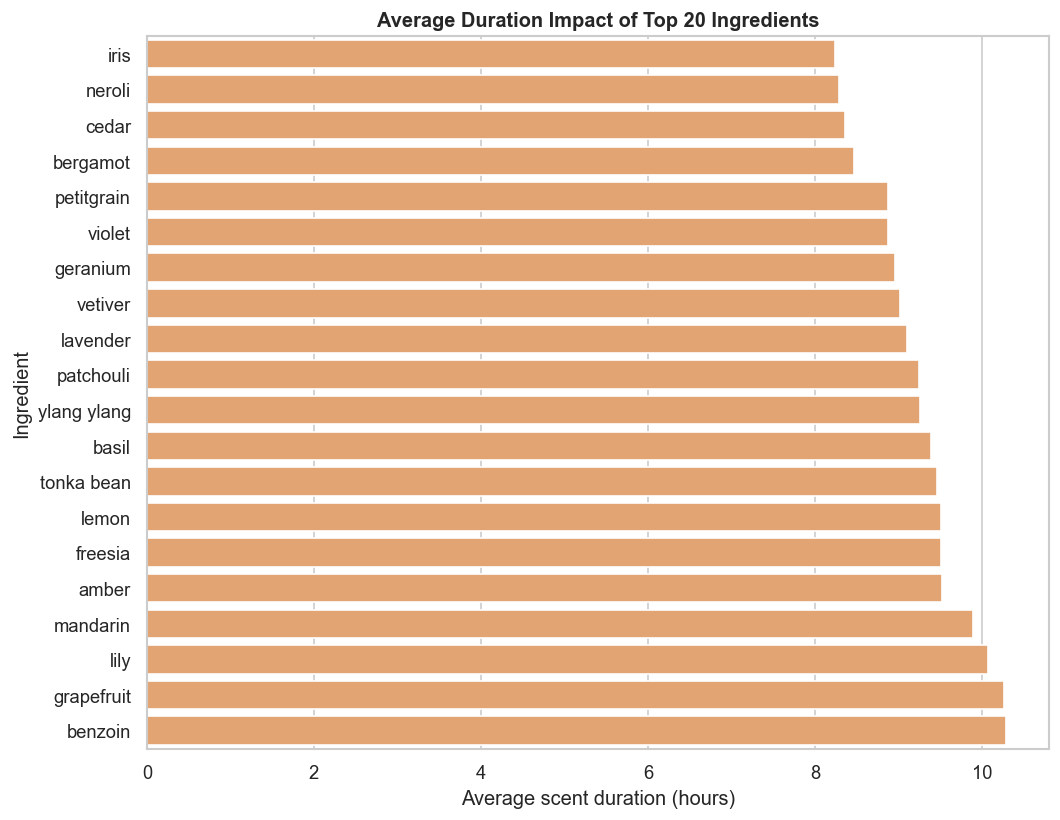

In [8]:
def parse_ingredients(value):
    if pd.isna(value):
        return []
    return [
        item.strip().lower().replace("-", " ").replace("_", " ")
        for item in str(value).split(",")
        if item.strip()
    ]

df["ingredient_list"] = df["Ingredients"].apply(parse_ingredients)
ingredient_rows = df[["FragranceID", "ScentDuration_Hours", "ingredient_list"]].explode("ingredient_list")
ingredient_rows = ingredient_rows.dropna(subset=["ingredient_list"])
ingredient_rows = ingredient_rows[ingredient_rows["ingredient_list"].astype(str).str.len() > 0]

ingredient_frequency = (
    ingredient_rows.groupby("ingredient_list")
    .agg(
        appearances=("FragranceID", "count"),
        avg_scent_duration=("ScentDuration_Hours", "mean"),
        std_scent_duration=("ScentDuration_Hours", "std"),
    )
    .sort_values(["appearances", "avg_scent_duration"], ascending=[False, False])
)

top20_ingredients = ingredient_frequency.head(20).reset_index()
display(top20_ingredients)

plt.figure(figsize=(9, 7))
sns.barplot(data=top20_ingredients, y="ingredient_list", x="appearances", color="#2A9D8F")
plt.title("Top 20 Most Common Ingredients")
plt.xlabel("Appearances")
plt.ylabel("Ingredient")
plt.tight_layout()
plt.savefig(FIG_DIR / "top20_ingredient_frequency.png", bbox_inches="tight")
plt.show()

plt.figure(figsize=(9, 7))
sns.barplot(data=top20_ingredients.sort_values("avg_scent_duration"), y="ingredient_list", x="avg_scent_duration", color="#F4A261")
plt.title("Average Duration Impact of Top 20 Ingredients")
plt.xlabel("Average scent duration (hours)")
plt.ylabel("Ingredient")
plt.tight_layout()
plt.savefig(FIG_DIR / "top20_ingredient_avg_duration.png", bbox_inches="tight")
plt.show()

## 2. Feature Engineering

The feature set combines fragrance structure, physical chemistry, categorical encodings, and ingredient flags. Multi-label ingredient encoding preserves formulation-level ingredient signals without treating the comma-separated list as unstructured text.

In [9]:
KEY_FIXATIVES = [
    "musk",
    "amber",
    "vanilla",
    "sandalwood",
    "patchouli",
    "vetiver",
    "oakmoss",
    "benzoin",
    "tonka bean",
    "cedar",
]


def concentration_tier(concentration):
    if pd.isna(concentration):
        return "Unknown"
    if concentration < 5:
        return "EdC"
    if concentration <= 15:
        return "EdT"
    if concentration <= 20:
        return "EdP"
    return "Perfume"


def add_engineered_features(data):
    engineered = data.copy()
    if "ingredient_list" not in engineered.columns:
        engineered["ingredient_list"] = engineered["Ingredients"].apply(parse_ingredients)

    engineered["base_to_top_ratio"] = engineered["BaseNotes_Pct"] / (engineered["TopNotes_Pct"] + 1)
    engineered["fixative_score"] = engineered["BaseNotes_Pct"] * engineered["LogP"]
    engineered["volatility_adjusted_concentration"] = engineered["Concentration_Pct"] / (engineered["VolatilityScore"] + 0.01)
    engineered["ingredient_complexity"] = engineered["NumIngredients"] * engineered["AvgMolecularWeight"]
    engineered["boiling_vapor_ratio"] = engineered["BoilingPoint_C"] / (engineered["VaporPressure_Pa"] + 1)
    engineered["concentration_tier"] = engineered["Concentration_Pct"].apply(concentration_tier)

    ingredient_text = engineered["ingredient_list"].apply(lambda values: " | ".join(values))
    for fixative in KEY_FIXATIVES:
        safe_name = fixative.replace(" ", "_")
        engineered[f"has_{safe_name}"] = ingredient_text.str.contains(re.escape(fixative), case=False, na=False).astype(int)

    fixative_cols = [f"has_{fixative.replace(' ', '_')}" for fixative in KEY_FIXATIVES]
    engineered["fixative_count"] = engineered[fixative_cols].sum(axis=1)
    return engineered


df_fe = add_engineered_features(df)

label_encoders = {}
for col in ["FragranceFamily", "ApplicationType", "concentration_tier"]:
    encoder = LabelEncoder()
    df_fe[f"{col}_encoded"] = encoder.fit_transform(df_fe[col].astype(str).fillna("Unknown"))
    label_encoders[col] = encoder

mlb = MultiLabelBinarizer()
ingredient_matrix = mlb.fit_transform(df_fe["ingredient_list"])
ingredient_feature_names = [f"ingredient__{name}" for name in mlb.classes_]
ingredient_df = pd.DataFrame(ingredient_matrix, columns=ingredient_feature_names, index=df_fe.index)

model_df = pd.concat([df_fe, ingredient_df], axis=1)

base_feature_cols = [
    "Concentration_Pct",
    "TopNotes_Pct",
    "MiddleNotes_Pct",
    "BaseNotes_Pct",
    "NumIngredients",
    "AvgMolecularWeight",
    "VolatilityScore",
    "LogP",
    "VaporPressure_Pa",
    "BoilingPoint_C",
    "base_to_top_ratio",
    "fixative_score",
    "volatility_adjusted_concentration",
    "ingredient_complexity",
    "boiling_vapor_ratio",
    "FragranceFamily_encoded",
    "ApplicationType_encoded",
    "concentration_tier_encoded",
    "fixative_count",
]
fixative_feature_cols = [f"has_{fixative.replace(' ', '_')}" for fixative in KEY_FIXATIVES]
feature_cols = base_feature_cols + fixative_feature_cols + ingredient_feature_names

X = model_df[feature_cols].replace([np.inf, -np.inf], np.nan)
y_reg = model_df["ScentDuration_Hours"]
y_class_raw = model_df["LongevityCategory"].astype(str)

print(f"Engineered modeling matrix: {X.shape[0]} rows x {X.shape[1]} features")
display(model_df[base_feature_cols + fixative_feature_cols].head())

Engineered modeling matrix: 500 rows x 59 features


,Concentration_Pct,TopNotes_Pct,MiddleNotes_Pct,BaseNotes_Pct,NumIngredients,AvgMolecularWeight,VolatilityScore,LogP,VaporPressure_Pa,BoilingPoint_C,...,has_musk,has_amber,has_vanilla,has_sandalwood,has_patchouli,has_vetiver,has_oakmoss,has_benzoin,has_tonka_bean,has_cedar
0,5.9,36.4,33.7,29.9,3,216,0.429,3.39,40,262,...,0,1,0,0,0,0,0,0,0,0
1,17.9,36.1,35.0,28.9,4,182,0.523,3.97,76,241,...,0,0,0,0,0,0,1,1,0,0
2,1.8,23.9,35.0,41.1,8,189,0.445,3.31,18,276,...,0,0,0,0,0,0,0,1,0,1
3,4.4,36.2,22.4,41.4,6,189,0.458,3.22,20,274,...,0,0,0,0,1,0,1,0,0,1
4,5.1,26.5,20.7,52.8,6,185,0.276,3.85,9,271,...,1,0,0,0,0,0,0,0,0,0


## 3. Regression Models

Seven regression models are trained with an 80/20 split and 5-fold cross-validation. The evaluation table includes train and test RMSE, MAE, and R-squared, plus cross-validated RMSE.

In [10]:
def rmse(y_true, y_pred):
    return math.sqrt(mean_squared_error(y_true, y_pred))


X_train, X_test, y_train, y_test = train_test_split(
    X, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

try:
    from xgboost import XGBRegressor
except Exception as exc:
    XGBRegressor = None
    print(f"XGBoost unavailable: {exc}")

try:
    from lightgbm import LGBMRegressor
except Exception as exc:
    LGBMRegressor = None
    print(f"LightGBM unavailable: {exc}")


def scaled_pipeline(model):
    return Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
            ("model", model),
        ]
    )


def tree_pipeline(model):
    return Pipeline(
        steps=[
            ("imputer", SimpleImputer(strategy="median")),
            ("model", model),
        ]
    )


regression_models = {
    "Linear Regression": scaled_pipeline(LinearRegression()),
    "Ridge Regression": scaled_pipeline(Ridge(random_state=RANDOM_STATE)),
    "Random Forest Regressor": tree_pipeline(
        RandomForestRegressor(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1)
    ),
    "SVR": scaled_pipeline(SVR(kernel="rbf")),
    "Gradient Boosting Regressor": tree_pipeline(
        GradientBoostingRegressor(random_state=RANDOM_STATE)
    ),
}

if XGBRegressor is not None:
    regression_models["XGBoost Regressor"] = tree_pipeline(
        XGBRegressor(
            n_estimators=500,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="reg:squarederror",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    )

if LGBMRegressor is not None:
    regression_models["LightGBM Regressor"] = tree_pipeline(
        LGBMRegressor(
            n_estimators=500,
            learning_rate=0.05,
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbose=-1,
        )
    )

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
regression_results = []
fitted_regression_models = {}
regression_predictions = {}

for name, model in regression_models.items():
    fitted = clone(model)
    fitted.fit(X_train, y_train)
    fitted_regression_models[name] = fitted

    train_pred = fitted.predict(X_train)
    test_pred = fitted.predict(X_test)
    regression_predictions[name] = test_pred

    cv_scores = cross_validate(
        clone(model),
        X,
        y_reg,
        cv=cv,
        scoring={
            "rmse": "neg_root_mean_squared_error",
            "mae": "neg_mean_absolute_error",
            "r2": "r2",
        },
        n_jobs=-1,
        error_score="raise",
    )

    regression_results.append(
        {
            "model": name,
            "train_rmse": rmse(y_train, train_pred),
            "test_rmse": rmse(y_test, test_pred),
            "train_mae": mean_absolute_error(y_train, train_pred),
            "test_mae": mean_absolute_error(y_test, test_pred),
            "train_r2": r2_score(y_train, train_pred),
            "test_r2": r2_score(y_test, test_pred),
            "cv_rmse_mean": -cv_scores["test_rmse"].mean(),
            "cv_rmse_std": cv_scores["test_rmse"].std(),
            "cv_mae_mean": -cv_scores["test_mae"].mean(),
            "cv_r2_mean": cv_scores["test_r2"].mean(),
        }
    )

regression_performance = pd.DataFrame(regression_results).sort_values("test_rmse")
display(regression_performance.style.format(precision=4))

regression_performance.to_csv(OUTPUT_DIR / "regression_model_performance.csv", index=False)

,model,train_rmse,test_rmse,train_mae,test_mae,train_r2,test_r2,cv_rmse_mean,cv_rmse_std,cv_mae_mean,cv_r2_mean
6,LightGBM Regressor,0.0744,1.0010,0.0499,0.7315,0.9999,0.9853,1.2184,0.1664,0.8385,0.9773
4,Gradient Boosting Regressor,0.4593,1.0940,0.3333,0.7810,0.9968,0.9825,1.2392,0.1232,0.8597,0.9767
5,XGBoost Regressor,0.0481,1.1040,0.0351,0.7525,1.0000,0.9822,1.2073,0.1490,0.8143,0.9778
2,Random Forest Regressor,0.6162,1.3424,0.4171,0.9676,0.9943,0.9736,1.5157,0.1719,1.0691,0.9651
0,Linear Regression,2.2861,2.4049,1.7573,1.8915,0.9219,0.9154,2.5773,0.1757,1.9854,0.9005
1,Ridge Regression,2.2888,2.4129,1.7583,1.8835,0.9218,0.9148,2.5652,0.1780,1.9757,0.9015
3,SVR,5.5616,6.0693,3.6395,4.0614,0.5380,0.4612,6.2319,0.2198,4.2758,0.4192


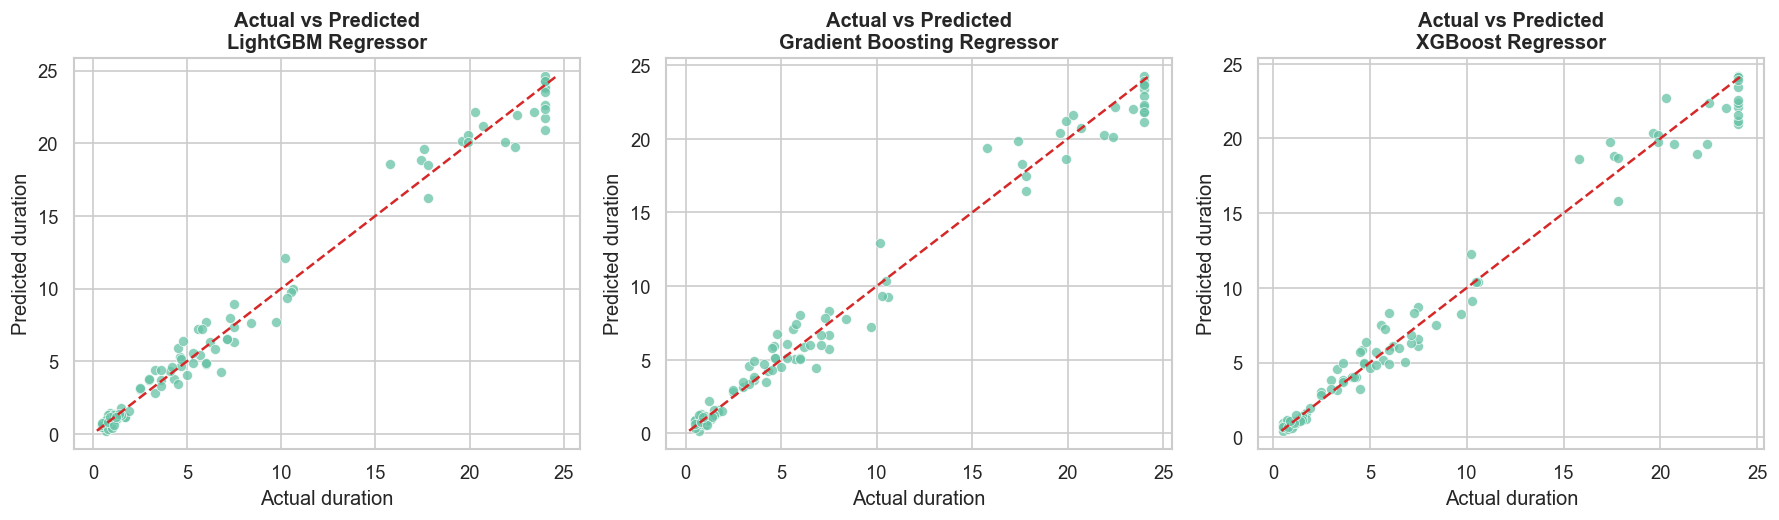

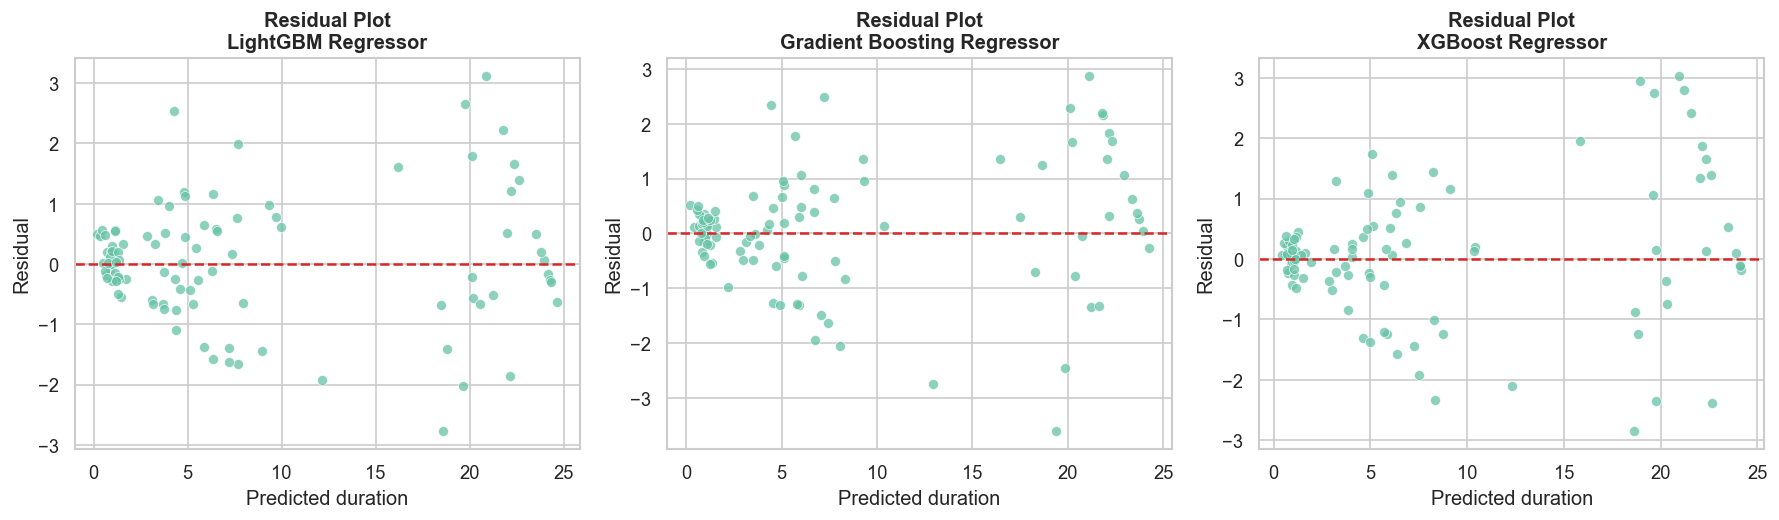

In [11]:
top3_regression_names = regression_performance.head(3)["model"].tolist()

fig, axes = plt.subplots(1, len(top3_regression_names), figsize=(5 * len(top3_regression_names), 4.5), squeeze=False)
for ax, name in zip(axes.ravel(), top3_regression_names):
    preds = regression_predictions[name]
    sns.scatterplot(x=y_test, y=preds, ax=ax, alpha=0.75)
    min_val = min(y_test.min(), np.min(preds))
    max_val = max(y_test.max(), np.max(preds))
    ax.plot([min_val, max_val], [min_val, max_val], color="#D62828", linestyle="--", linewidth=1.5)
    ax.set_title(f"Actual vs Predicted\n{name}")
    ax.set_xlabel("Actual duration")
    ax.set_ylabel("Predicted duration")

plt.tight_layout()
plt.savefig(FIG_DIR / "actual_vs_predicted_top3_regressors.png", bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, len(top3_regression_names), figsize=(5 * len(top3_regression_names), 4.5), squeeze=False)
for ax, name in zip(axes.ravel(), top3_regression_names):
    preds = regression_predictions[name]
    residuals = y_test - preds
    sns.scatterplot(x=preds, y=residuals, ax=ax, alpha=0.75)
    ax.axhline(0, color="#D62828", linestyle="--", linewidth=1.5)
    ax.set_title(f"Residual Plot\n{name}")
    ax.set_xlabel("Predicted duration")
    ax.set_ylabel("Residual")

plt.tight_layout()
plt.savefig(FIG_DIR / "residual_plots_top3_regressors.png", bbox_inches="tight")
plt.show()

## 4. Classification Models

This section predicts `LongevityCategory` directly from formulation and ingredient features. `ScentDuration_Hours` is intentionally excluded from the classifier feature matrix to avoid target leakage.

,model,accuracy,weighted_f1
1,Random Forest Classifier,0.8700,0.8729
3,LightGBM Classifier,0.8500,0.8480
0,Logistic Regression,0.8400,0.8428
2,XGBoost Classifier,0.8400,0.8399



Classification report: Random Forest Classifier
              precision    recall  f1-score   support

        Long       0.65      0.69      0.67        16
      Medium       0.67      0.71      0.69        17
       Short       1.00      0.94      0.97        32
   Very Long       0.97      0.97      0.97        35

    accuracy                           0.87       100
   macro avg       0.82      0.83      0.82       100
weighted avg       0.88      0.87      0.87       100



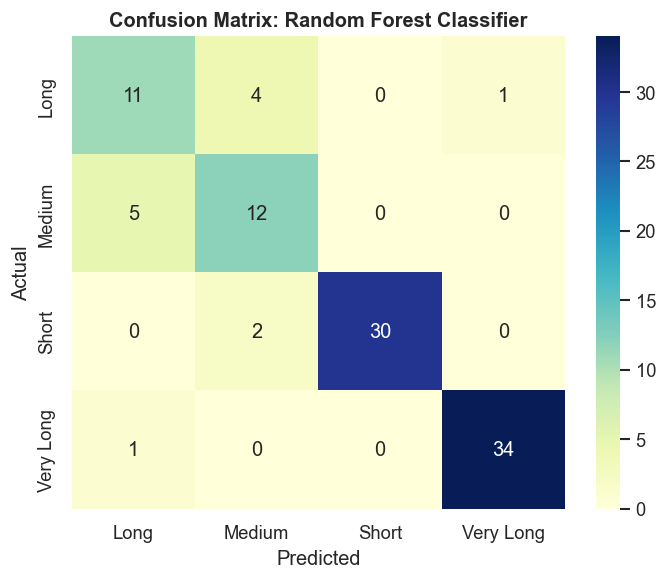


Classification report: LightGBM Classifier
              precision    recall  f1-score   support

        Long       0.62      0.50      0.55        16
      Medium       0.65      0.76      0.70        17
       Short       1.00      0.94      0.97        32
   Very Long       0.92      0.97      0.94        35

    accuracy                           0.85       100
   macro avg       0.80      0.79      0.79       100
weighted avg       0.85      0.85      0.85       100



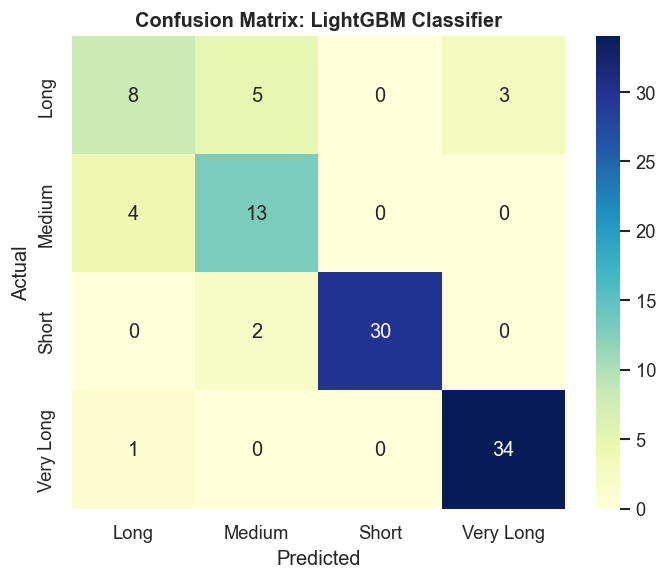


Classification report: Logistic Regression
              precision    recall  f1-score   support

        Long       0.56      0.56      0.56        16
      Medium       0.63      0.71      0.67        17
       Short       1.00      0.91      0.95        32
   Very Long       0.94      0.97      0.96        35

    accuracy                           0.84       100
   macro avg       0.78      0.79      0.78       100
weighted avg       0.85      0.84      0.84       100



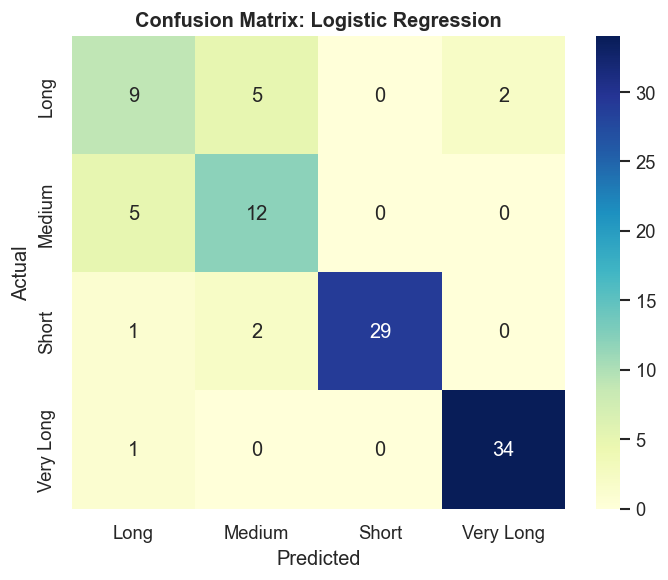


Classification report: XGBoost Classifier
              precision    recall  f1-score   support

        Long       0.64      0.56      0.60        16
      Medium       0.58      0.65      0.61        17
       Short       0.94      0.94      0.94        32
   Very Long       0.97      0.97      0.97        35

    accuracy                           0.84       100
   macro avg       0.78      0.78      0.78       100
weighted avg       0.84      0.84      0.84       100



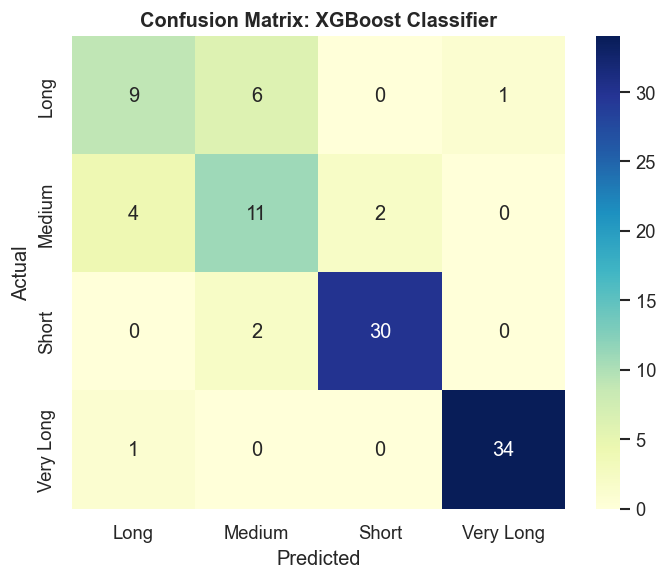

In [12]:
y_class_encoder = LabelEncoder()
y_class = y_class_encoder.fit_transform(y_class_raw)

Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X,
    y_class,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_class if pd.Series(y_class).value_counts().min() >= 2 else None,
)

try:
    from xgboost import XGBClassifier
except Exception as exc:
    XGBClassifier = None
    print(f"XGBoost classifier unavailable: {exc}")

try:
    from lightgbm import LGBMClassifier
except Exception as exc:
    LGBMClassifier = None
    print(f"LightGBM classifier unavailable: {exc}")

classification_models = {
    "Logistic Regression": scaled_pipeline(
        LogisticRegression(max_iter=3000, class_weight="balanced", random_state=RANDOM_STATE)
    ),
    "Random Forest Classifier": tree_pipeline(
        RandomForestClassifier(n_estimators=400, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1)
    ),
}

if XGBClassifier is not None:
    classification_models["XGBoost Classifier"] = tree_pipeline(
        XGBClassifier(
            n_estimators=400,
            learning_rate=0.05,
            max_depth=4,
            subsample=0.9,
            colsample_bytree=0.9,
            objective="multi:softprob",
            eval_metric="mlogloss",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )
    )

if LGBMClassifier is not None:
    classification_models["LightGBM Classifier"] = tree_pipeline(
        LGBMClassifier(
            n_estimators=400,
            learning_rate=0.05,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
            verbose=-1,
        )
    )

classification_results = []
fitted_classification_models = {}

for name, model in classification_models.items():
    fitted = clone(model)
    fitted.fit(Xc_train, yc_train)
    fitted_classification_models[name] = fitted
    pred = fitted.predict(Xc_test)
    classification_results.append(
        {
            "model": name,
            "accuracy": accuracy_score(yc_test, pred),
            "weighted_f1": f1_score(yc_test, pred, average="weighted"),
        }
    )

classification_performance = pd.DataFrame(classification_results).sort_values("weighted_f1", ascending=False)
display(classification_performance.style.format(precision=4))
classification_performance.to_csv(OUTPUT_DIR / "classification_model_performance.csv", index=False)

for name in classification_performance["model"].tolist():
    pred = fitted_classification_models[name].predict(Xc_test)
    print(f"\nClassification report: {name}")
    print(classification_report(yc_test, pred, target_names=y_class_encoder.classes_))

    cm = confusion_matrix(yc_test, pred)
    plt.figure(figsize=(6, 5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="YlGnBu",
        xticklabels=y_class_encoder.classes_,
        yticklabels=y_class_encoder.classes_,
    )
    plt.title(f"Confusion Matrix: {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    safe_name = re.sub(r"[^a-z0-9]+", "_", name.lower()).strip("_")
    plt.savefig(FIG_DIR / f"confusion_matrix_{safe_name}.png", bbox_inches="tight")
    plt.show()

## 5. Hyperparameter Tuning

The best baseline regression model is tuned using `RandomizedSearchCV`. The tuned model is retained only if it improves or matches the baseline test RMSE.

In [13]:
best_baseline_name = regression_performance.iloc[0]["model"]
best_baseline_model = fitted_regression_models[best_baseline_name]
best_baseline_rmse = regression_performance.iloc[0]["test_rmse"]

param_grids = {
    "Random Forest Regressor": {
        "model__n_estimators": [200, 400, 700, 1000],
        "model__max_depth": [None, 4, 6, 8, 12, 16],
        "model__min_samples_split": [2, 4, 8, 12],
        "model__min_samples_leaf": [1, 2, 4, 6],
        "model__max_features": ["sqrt", "log2", 0.6, 0.8, 1.0],
    },
    "Gradient Boosting Regressor": {
        "model__n_estimators": [100, 200, 400, 700],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
        "model__max_depth": [2, 3, 4, 5],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__min_samples_leaf": [1, 2, 4, 6],
    },
    "XGBoost Regressor": {
        "model__n_estimators": [200, 400, 700, 1000],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
        "model__max_depth": [2, 3, 4, 5, 6],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.7, 0.85, 1.0],
        "model__reg_lambda": [0.5, 1.0, 2.0, 5.0],
    },
    "LightGBM Regressor": {
        "model__n_estimators": [200, 400, 700, 1000],
        "model__learning_rate": [0.01, 0.03, 0.05, 0.08, 0.1],
        "model__num_leaves": [15, 31, 63, 127],
        "model__max_depth": [-1, 3, 5, 7, 9],
        "model__subsample": [0.7, 0.85, 1.0],
        "model__colsample_bytree": [0.7, 0.85, 1.0],
    },
    "Ridge Regression": {
        "model__alpha": np.logspace(-3, 3, 30),
    },
    "SVR": {
        "model__C": np.logspace(-1, 3, 20),
        "model__epsilon": [0.01, 0.05, 0.1, 0.25, 0.5],
        "model__gamma": ["scale", "auto"],
    },
    "Linear Regression": {},
}

search_space = param_grids.get(best_baseline_name, {})
if search_space:
    tuner = RandomizedSearchCV(
        estimator=clone(regression_models[best_baseline_name]),
        param_distributions=search_space,
        n_iter=min(35, max(1, np.prod([len(v) for v in search_space.values()]) if search_space else 1)),
        scoring="neg_root_mean_squared_error",
        cv=cv,
        random_state=RANDOM_STATE,
        n_jobs=-1,
        verbose=1,
    )
    tuner.fit(X_train, y_train)
    tuned_model = tuner.best_estimator_
    tuned_pred = tuned_model.predict(X_test)
    tuned_rmse = rmse(y_test, tuned_pred)
    print(f"Best baseline model: {best_baseline_name}")
    print(f"Baseline test RMSE: {best_baseline_rmse:.4f}")
    print(f"Tuned test RMSE: {tuned_rmse:.4f}")
    print(f"Best parameters: {tuner.best_params_}")
else:
    tuned_model = best_baseline_model
    tuned_rmse = best_baseline_rmse
    print(f"No useful tuning grid for {best_baseline_name}; using baseline model.")

if tuned_rmse <= best_baseline_rmse:
    best_model = tuned_model
    best_model_name = f"Tuned {best_baseline_name}" if search_space else best_baseline_name
    best_model_rmse = tuned_rmse
else:
    best_model = best_baseline_model
    best_model_name = best_baseline_name
    best_model_rmse = best_baseline_rmse

improvement = best_baseline_rmse - best_model_rmse
print(f"Selected model: {best_model_name}")
print(f"RMSE improvement vs baseline best: {improvement:.4f} hours")

Fitting 5 folds for each of 35 candidates, totalling 175 fits


Best baseline model: LightGBM Regressor
Baseline test RMSE: 1.0010
Tuned test RMSE: 1.0591
Best parameters: {'model__subsample': 0.85, 'model__num_leaves': 15, 'model__n_estimators': 200, 'model__max_depth': 3, 'model__learning_rate': 0.08, 'model__colsample_bytree': 0.7}
Selected model: LightGBM Regressor
RMSE improvement vs baseline best: 0.0000 hours


## 6. Feature Importance and SHAP Interpretability

This section explains which formulation and ingredient signals are most associated with predicted scent duration. SHAP is used when available; model-native or permutation-style fallbacks are used for feature importance if needed.

,feature,importance
0,volatility_adjusted_concentration,959
1,Concentration_Pct,841
2,FragranceFamily_encoded,536
3,LogP,512
4,ingredient_complexity,424
5,AvgMolecularWeight,403
6,fixative_score,374
7,MiddleNotes_Pct,345
8,VolatilityScore,332
9,base_to_top_ratio,328


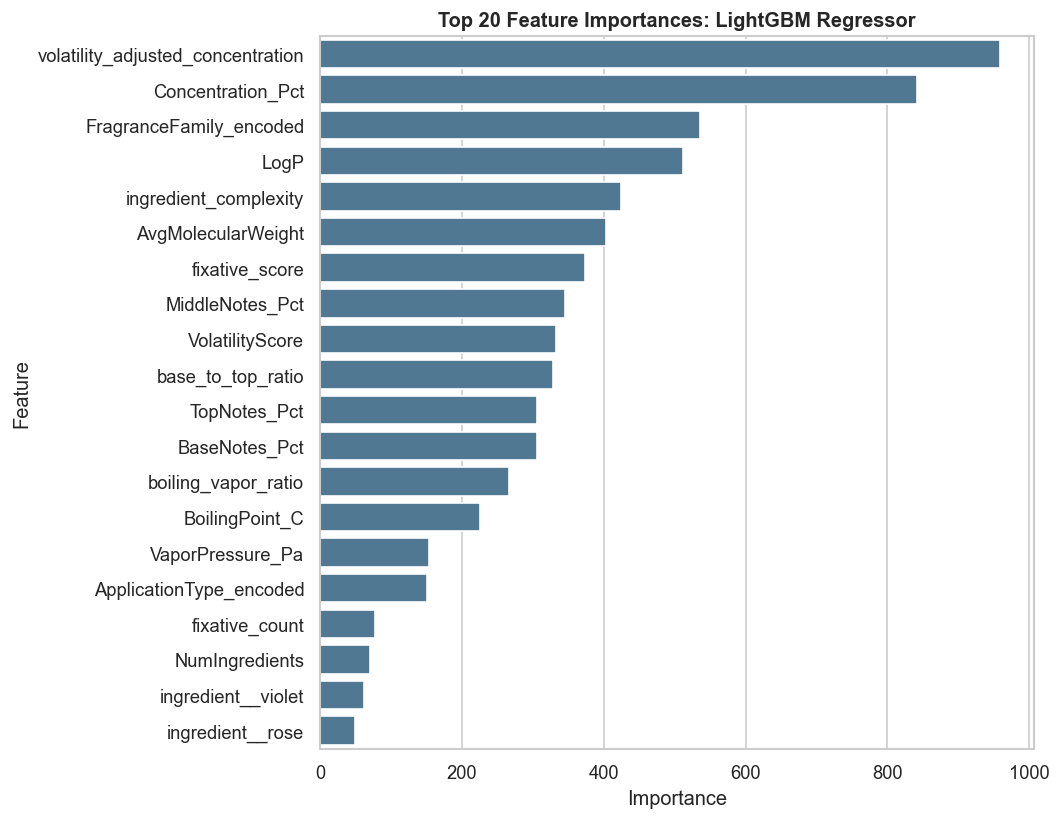

In [14]:
def get_feature_importance(model, X_reference, y_reference=None):
    final_model = model.named_steps.get("model", model) if isinstance(model, Pipeline) else model
    if hasattr(final_model, "feature_importances_"):
        return pd.DataFrame({"feature": X_reference.columns, "importance": final_model.feature_importances_}).sort_values("importance", ascending=False)
    if hasattr(final_model, "coef_"):
        coef = np.ravel(final_model.coef_)
        return pd.DataFrame({"feature": X_reference.columns, "importance": np.abs(coef)}).sort_values("importance", ascending=False)

    # Fallback: simple univariate absolute correlation with target.
    values = []
    for col in X_reference.columns:
        joined = pd.concat([X_reference[col], y_reference], axis=1).dropna()
        corr_value = abs(joined.iloc[:, 0].corr(joined.iloc[:, 1])) if len(joined) > 2 else 0
        values.append({"feature": col, "importance": 0 if pd.isna(corr_value) else corr_value})
    return pd.DataFrame(values).sort_values("importance", ascending=False)


feature_importance = get_feature_importance(best_model, X_train, y_train).reset_index(drop=True)
display(feature_importance.head(20))
feature_importance.to_csv(OUTPUT_DIR / "feature_importance.csv", index=False)

plt.figure(figsize=(9, 7))
sns.barplot(data=feature_importance.head(20), y="feature", x="importance", color="#457B9D")
plt.title(f"Top 20 Feature Importances: {best_model_name}")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(FIG_DIR / "top20_feature_importance.png", bbox_inches="tight")
plt.show()

PermutationExplainer explainer:   1%|          | 1/100 [00:00<?, ?it/s]

PermutationExplainer explainer:   3%|▎         | 3/100 [00:15<00:19,  4.99it/s]

PermutationExplainer explainer:   4%|▍         | 4/100 [00:15<00:26,  3.69it/s]

PermutationExplainer explainer:   5%|▌         | 5/100 [00:15<00:28,  3.39it/s]

PermutationExplainer explainer:   6%|▌         | 6/100 [00:16<00:29,  3.14it/s]

...

PermutationExplainer explainer:  98%|█████████▊| 98/100 [00:48<00:00,  3.11it/s]

PermutationExplainer explainer:  99%|█████████▉| 99/100 [00:48<00:00,  3.13it/s]

PermutationExplainer explainer: 100%|██████████| 100/100 [00:48<00:00,  3.07it/s]

PermutationExplainer explainer: 101it [00:49,  3.12it/s]                         

PermutationExplainer explainer: 101it [00:49,  2.04it/s]

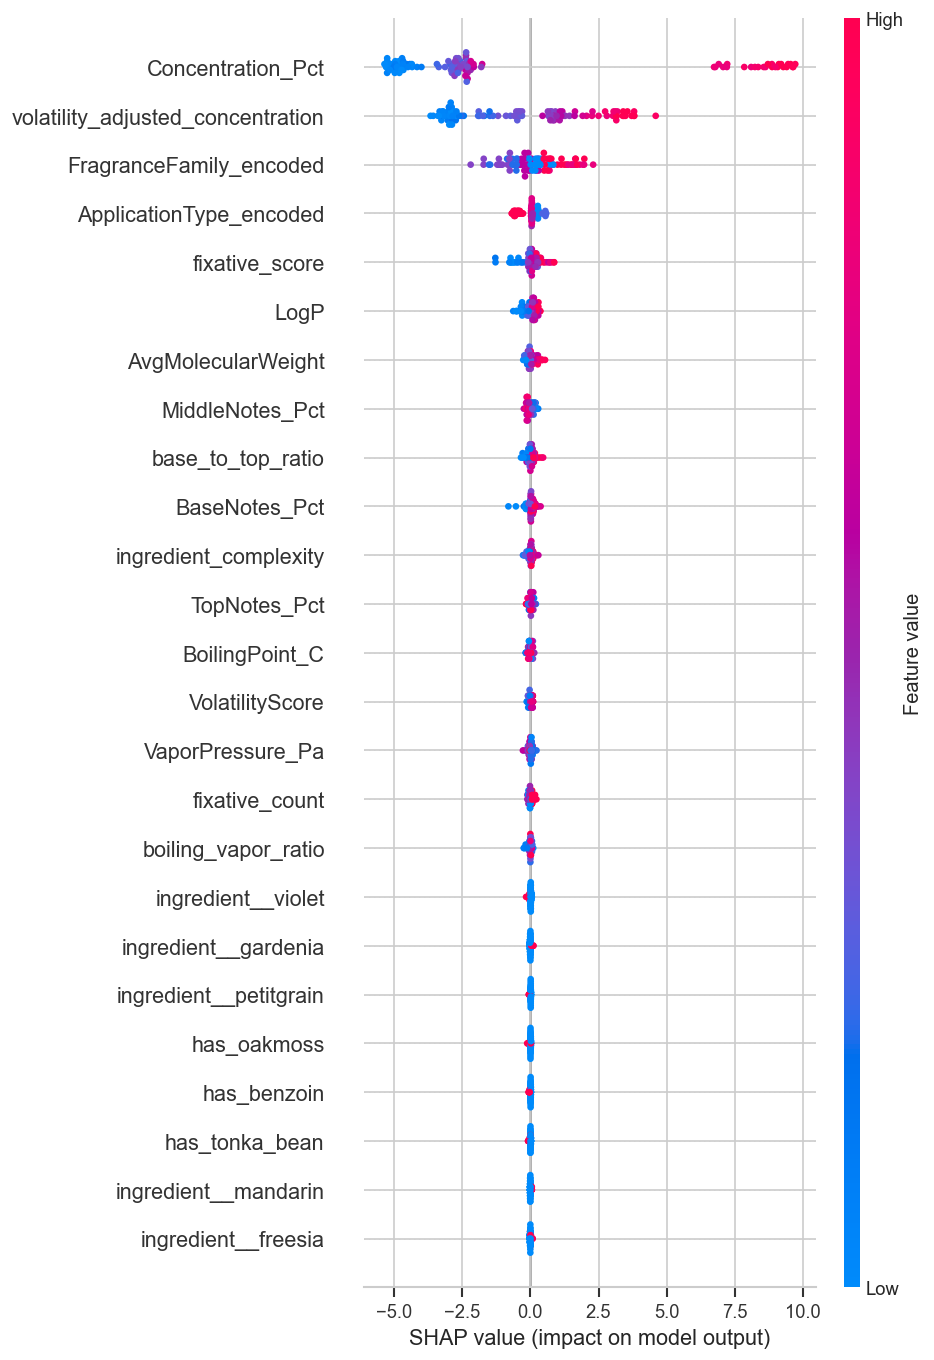

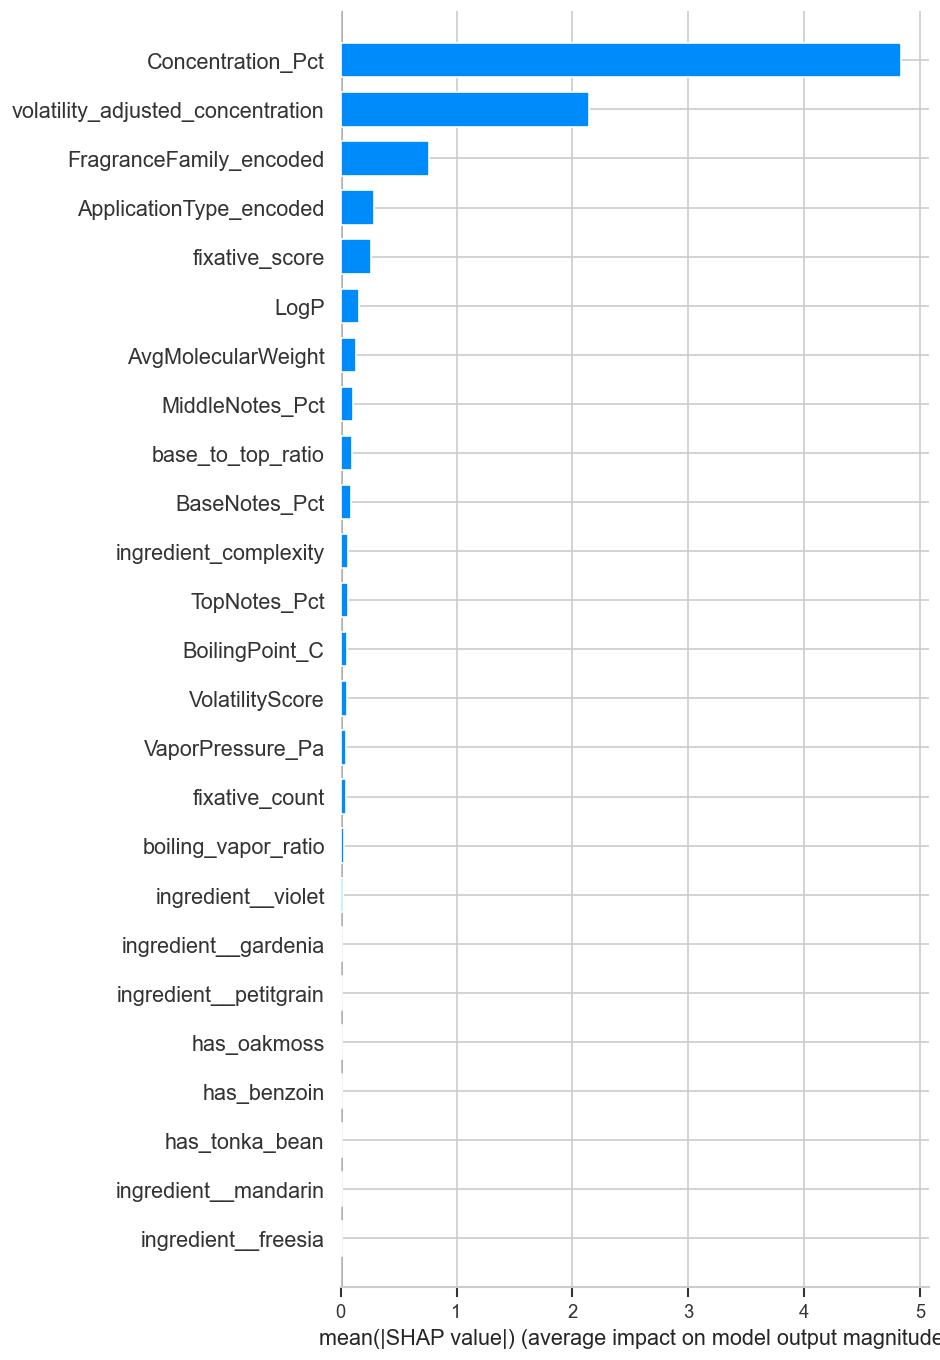

,feature,mean_abs_shap
0,Concentration_Pct,4.832202
12,volatility_adjusted_concentration,2.146126
15,FragranceFamily_encoded,0.763089
16,ApplicationType_encoded,0.287092
11,fixative_score,0.262333
7,LogP,0.163098
5,AvgMolecularWeight,0.131178
2,MiddleNotes_Pct,0.104825
10,base_to_top_ratio,0.097039
3,BaseNotes_Pct,0.093879


<Figure size 768x576 with 0 Axes>

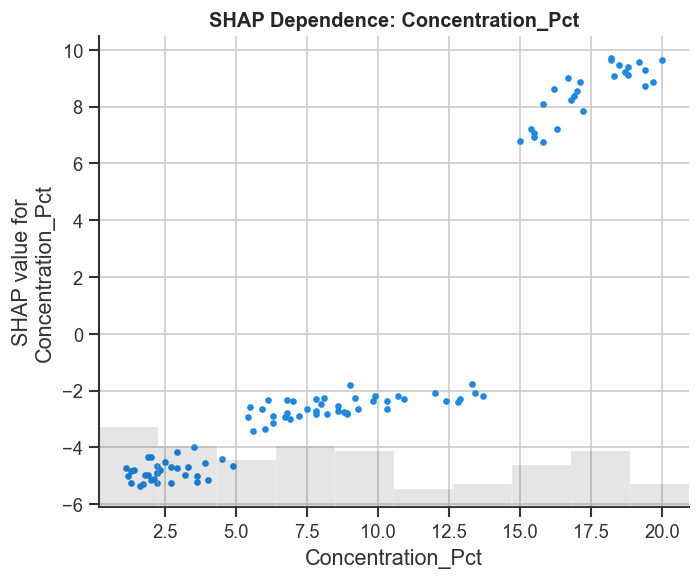

<Figure size 768x576 with 0 Axes>

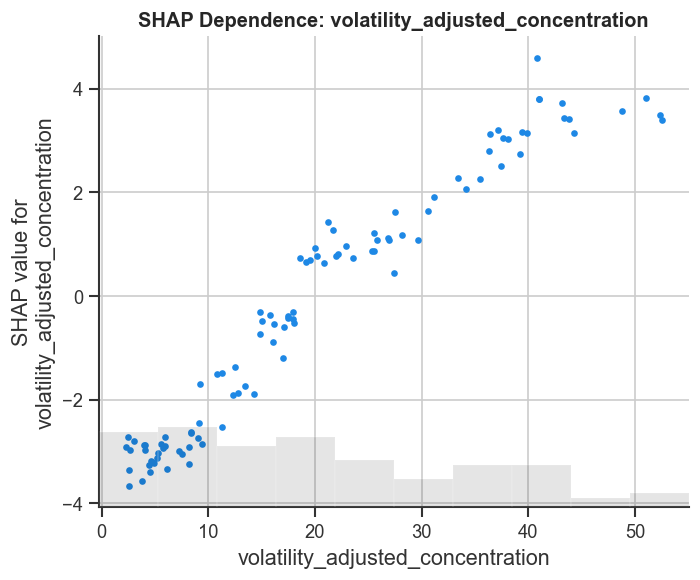

<Figure size 768x576 with 0 Axes>

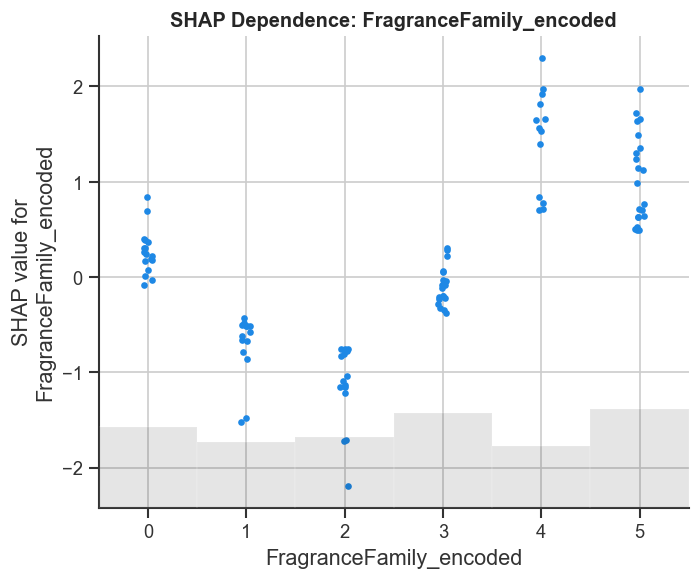

In [15]:
shap_values = None
shap_feature_matrix = None
shap_top_features = feature_importance.head(3)["feature"].tolist()

try:
    import shap

    shap_sample = X_test.sample(min(len(X_test), 150), random_state=RANDOM_STATE)
    background = X_train.sample(min(len(X_train), 100), random_state=RANDOM_STATE)
    explainer = shap.Explainer(best_model.predict, background)
    shap_values = explainer(shap_sample)
    shap_feature_matrix = shap_sample

    plt.figure()
    shap.summary_plot(shap_values, shap_feature_matrix, show=False, max_display=25)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "shap_summary_beeswarm.png", bbox_inches="tight")
    plt.show()

    plt.figure()
    shap.summary_plot(shap_values, shap_feature_matrix, plot_type="bar", show=False, max_display=25)
    plt.tight_layout()
    plt.savefig(FIG_DIR / "shap_summary_bar.png", bbox_inches="tight")
    plt.show()

    mean_abs_shap = np.abs(shap_values.values).mean(axis=0)
    shap_importance = pd.DataFrame({"feature": shap_feature_matrix.columns, "mean_abs_shap": mean_abs_shap}).sort_values("mean_abs_shap", ascending=False)
    shap_top_features = shap_importance.head(3)["feature"].tolist()
    display(shap_importance.head(20))
    shap_importance.to_csv(OUTPUT_DIR / "shap_feature_importance.csv", index=False)

    for feature in shap_top_features:
        plt.figure()
        shap.plots.scatter(shap_values[:, feature], show=False)
        plt.title(f"SHAP Dependence: {feature}")
        plt.tight_layout()
        safe_feature = re.sub(r"[^a-z0-9]+", "_", feature.lower()).strip("_")
        plt.savefig(FIG_DIR / f"shap_dependence_{safe_feature}.png", bbox_inches="tight")
        plt.show()
except Exception as exc:
    print(f"SHAP analysis could not be completed in this environment: {exc}")
    print("Feature importance fallback remains available in outputs/feature_importance.csv.")

In [16]:
def univariate_slope(data, feature, target="ScentDuration_Hours"):
    values = data[[feature, target]].replace([np.inf, -np.inf], np.nan).dropna()
    if len(values) < 3 or values[feature].nunique() < 2:
        return np.nan
    return np.polyfit(values[feature], values[target], 1)[0]


insights = []

base_slope = univariate_slope(model_df, "BaseNotes_Pct")
if not np.isnan(base_slope):
    insights.append(f"Base note concentration is a longevity lever: a 10 point increase in BaseNotes_Pct is associated with about {base_slope * 10:.2f} additional hours, before controlling for other factors.")

vol_slope = univariate_slope(model_df, "VolatilityScore")
if not np.isnan(vol_slope):
    insights.append(f"Volatility behaves as expected: a 0.10 increase in VolatilityScore is associated with about {vol_slope * 0.10:.2f} hours of duration change.")

fixative_lift = (
    model_df.assign(has_any_fixative=lambda x: x["fixative_count"] > 0)
    .groupby("has_any_fixative")["ScentDuration_Hours"]
    .mean()
)
if set(fixative_lift.index) == {False, True}:
    insights.append(f"Formulas containing at least one tracked fixative last {fixative_lift.loc[True] - fixative_lift.loc[False]:.2f} hours longer on average than formulas without tracked fixatives.")

application_means = model_df.groupby("ApplicationType")["ScentDuration_Hours"].mean().sort_values(ascending=False)
if len(application_means) >= 2:
    insights.append(f"Application format matters: {application_means.index[0]} has the highest average duration ({application_means.iloc[0]:.2f} hours), while {application_means.index[-1]} is lowest ({application_means.iloc[-1]:.2f} hours).")

top_feature = feature_importance.iloc[0]["feature"]
insights.append(f"The strongest model feature is `{top_feature}`, indicating that the model is primarily separating products using this signal.")

family_means = model_df.groupby("FragranceFamily")["ScentDuration_Hours"].mean().sort_values(ascending=False)
if len(family_means) >= 2:
    insights.append(f"Family profile is commercially relevant: {family_means.index[0]} fragrances average {family_means.iloc[0]:.2f} hours versus {family_means.index[-1]} at {family_means.iloc[-1]:.2f} hours.")

print("What drives scent duration?")
for idx, insight in enumerate(insights[:5], start=1):
    print(f"{idx}. {insight}")

with open(REPORT_DIR / "business_insights.json", "w", encoding="utf-8") as f:
    json.dump(insights[:5], f, indent=2)

What drives scent duration?
1. Base note concentration is a longevity lever: a 10 point increase in BaseNotes_Pct is associated with about 2.09 additional hours, before controlling for other factors.
2. Volatility behaves as expected: a 0.10 increase in VolatilityScore is associated with about -2.82 hours of duration change.
3. Application format matters: Eau de Parfum has the highest average duration (19.86 hours), while Body Lotion is lowest (0.92 hours).
4. The strongest model feature is `volatility_adjusted_concentration`, indicating that the model is primarily separating products using this signal.
5. Family profile is commercially relevant: Oriental fragrances average 10.51 hours versus Fresh at 6.60 hours.


## 7. Ingredient Impact Analysis and Recommendation

Ingredient longevity scoring ranks materials by average duration, variability, and support count. The recommender searches ingredient combinations and uses the trained regression model to suggest blends close to a target duration.

,ingredient,avg_scent_duration,std_scent_duration,appearances,ingredient_longevity_score
2,benzoin,10.284314,8.448677,102,5.044622
5,freesia,9.505505,7.936680,109,4.999668
12,lemon,9.501887,7.881346,106,4.999320
13,lily,10.074038,8.566666,104,4.900785
8,grapefruit,10.260606,8.790345,99,4.826371
1,basil,9.390741,8.243168,108,4.766248
24,tonka bean,9.460577,8.294652,104,4.737041
22,rose,9.355670,8.068960,97,4.729919
14,mandarin,9.885149,8.691172,101,4.717545
29,ylang ylang,9.259091,8.327090,110,4.675196


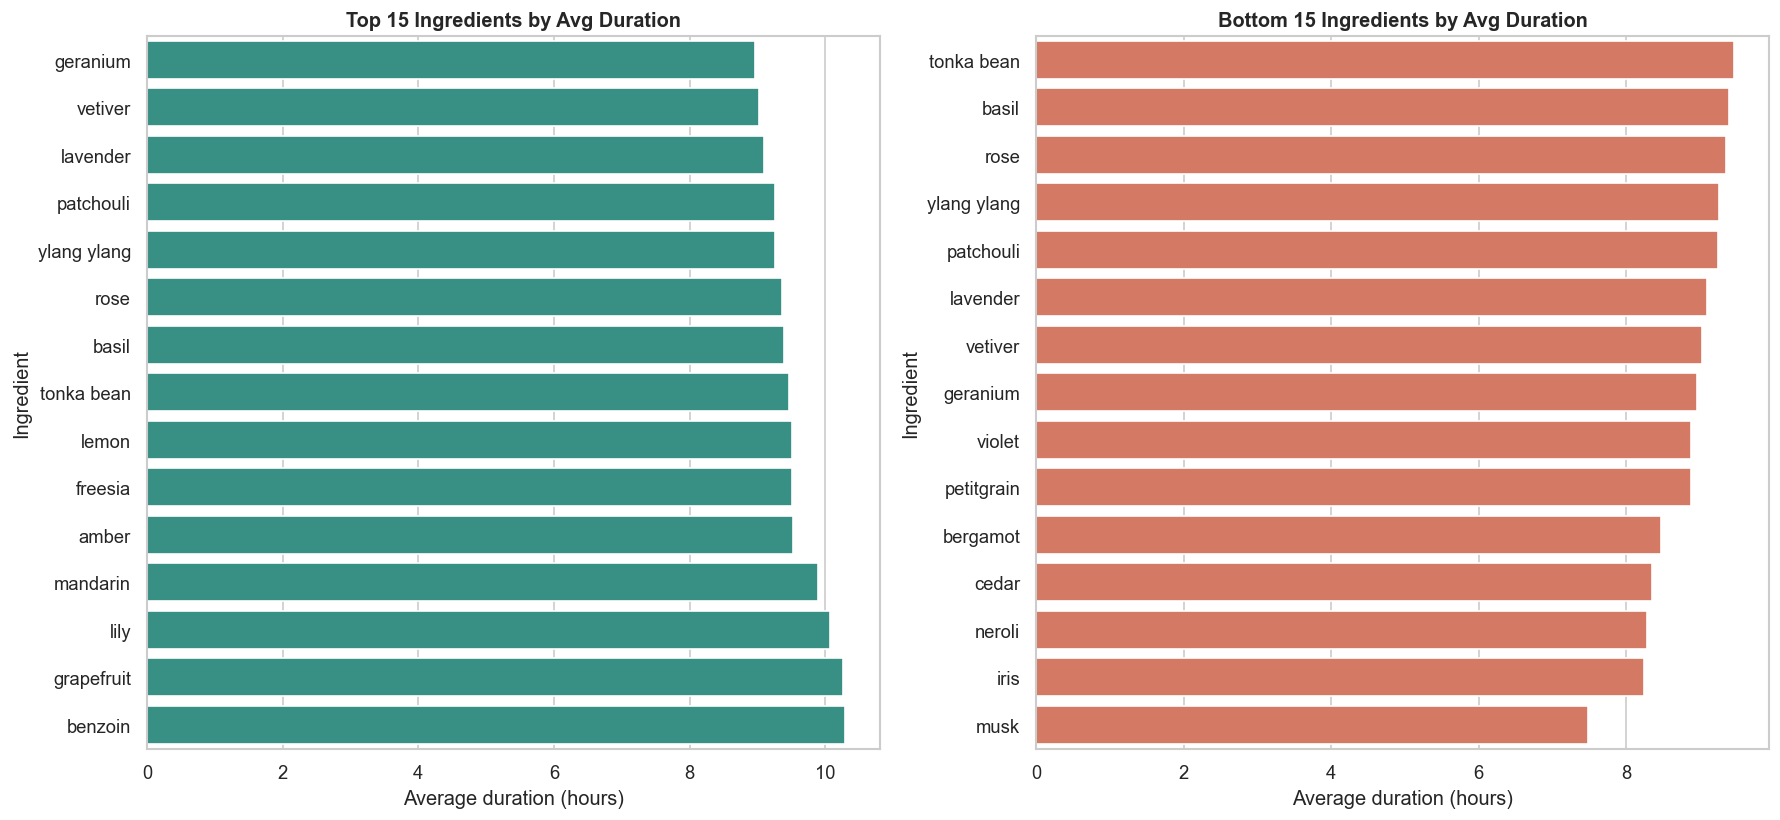

In [17]:
ingredient_impact = (
    ingredient_rows.groupby("ingredient_list")
    .agg(
        avg_scent_duration=("ScentDuration_Hours", "mean"),
        std_scent_duration=("ScentDuration_Hours", "std"),
        appearances=("ScentDuration_Hours", "count"),
    )
    .reset_index()
    .rename(columns={"ingredient_list": "ingredient"})
)

ingredient_impact["std_scent_duration"] = ingredient_impact["std_scent_duration"].fillna(0)
ingredient_impact["ingredient_longevity_score"] = (
    ingredient_impact["avg_scent_duration"]
    * np.log1p(ingredient_impact["appearances"])
    / (1 + ingredient_impact["std_scent_duration"])
)
ingredient_impact = ingredient_impact.sort_values("ingredient_longevity_score", ascending=False)

display(ingredient_impact.head(25))
ingredient_impact.to_csv(OUTPUT_DIR / "ingredient_longevity_scores.csv", index=False)

plot_candidates = ingredient_impact[ingredient_impact["appearances"] >= max(2, ingredient_impact["appearances"].quantile(0.25))]
top15 = plot_candidates.nlargest(15, "avg_scent_duration")
bottom15 = plot_candidates.nsmallest(15, "avg_scent_duration")

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
sns.barplot(data=top15.sort_values("avg_scent_duration"), y="ingredient", x="avg_scent_duration", ax=axes[0], color="#2A9D8F")
axes[0].set_title("Top 15 Ingredients by Avg Duration")
axes[0].set_xlabel("Average duration (hours)")
axes[0].set_ylabel("Ingredient")

sns.barplot(data=bottom15.sort_values("avg_scent_duration", ascending=False), y="ingredient", x="avg_scent_duration", ax=axes[1], color="#E76F51")
axes[1].set_title("Bottom 15 Ingredients by Avg Duration")
axes[1].set_xlabel("Average duration (hours)")
axes[1].set_ylabel("Ingredient")

plt.tight_layout()
plt.savefig(FIG_DIR / "top_bottom_ingredient_duration.png", bbox_inches="tight")
plt.show()

In [18]:
training_defaults = X_train.median(numeric_only=True).to_dict()


def encode_known_label(column, value):
    encoder = label_encoders[column]
    value = str(value)
    if value in encoder.classes_:
        return int(encoder.transform([value])[0])
    return int(encoder.transform([encoder.classes_[0]])[0])


def build_prediction_row(
    ingredients,
    fragrance_family=None,
    application_type=None,
    concentration_pct=None,
    top_notes_pct=None,
    middle_notes_pct=None,
    base_notes_pct=None,
):
    row = dict(training_defaults)

    if fragrance_family is not None:
        row["FragranceFamily_encoded"] = encode_known_label("FragranceFamily", fragrance_family)
    if application_type is not None:
        row["ApplicationType_encoded"] = encode_known_label("ApplicationType", application_type)
    if concentration_pct is not None:
        row["Concentration_Pct"] = concentration_pct
        tier = concentration_tier(concentration_pct)
        row["concentration_tier_encoded"] = encode_known_label("concentration_tier", tier)
    if top_notes_pct is not None:
        row["TopNotes_Pct"] = top_notes_pct
    if middle_notes_pct is not None:
        row["MiddleNotes_Pct"] = middle_notes_pct
    if base_notes_pct is not None:
        row["BaseNotes_Pct"] = base_notes_pct

    ingredient_values = [item.strip().lower().replace("-", " ").replace("_", " ") for item in ingredients]
    ingredient_text = " | ".join(ingredient_values)
    row["NumIngredients"] = len(ingredient_values)
    row["base_to_top_ratio"] = row["BaseNotes_Pct"] / (row["TopNotes_Pct"] + 1)
    row["fixative_score"] = row["BaseNotes_Pct"] * row["LogP"]
    row["volatility_adjusted_concentration"] = row["Concentration_Pct"] / (row["VolatilityScore"] + 0.01)
    row["ingredient_complexity"] = row["NumIngredients"] * row["AvgMolecularWeight"]
    row["boiling_vapor_ratio"] = row["BoilingPoint_C"] / (row["VaporPressure_Pa"] + 1)

    for fixative in KEY_FIXATIVES:
        row[f"has_{fixative.replace(' ', '_')}"] = int(fixative in ingredient_text)
    row["fixative_count"] = sum(row[f"has_{fixative.replace(' ', '_')}"] for fixative in KEY_FIXATIVES)

    for feature in ingredient_feature_names:
        ingredient_name = feature.replace("ingredient__", "", 1)
        row[feature] = int(ingredient_name in ingredient_values)

    return pd.DataFrame([row], columns=feature_cols).replace([np.inf, -np.inf], np.nan)


def recommend_ingredient_combinations(target_duration=12, combination_size=4, max_candidates=20, top_n=10):
    candidates = (
        ingredient_impact[ingredient_impact["appearances"] >= max(2, ingredient_impact["appearances"].quantile(0.25))]
        .sort_values("ingredient_longevity_score", ascending=False)
        .head(max_candidates)["ingredient"]
        .tolist()
    )
    rows = []
    for combo in itertools.combinations(candidates, combination_size):
        row = build_prediction_row(combo)
        predicted_duration = float(best_model.predict(row)[0])
        avg_observed_duration = ingredient_impact.set_index("ingredient").loc[list(combo), "avg_scent_duration"].mean()
        rows.append(
            {
                "ingredients": ", ".join(combo),
                "predicted_duration": predicted_duration,
                "avg_observed_ingredient_duration": avg_observed_duration,
                "target_gap": abs(predicted_duration - target_duration),
            }
        )
    return pd.DataFrame(rows).sort_values(["target_gap", "predicted_duration"]).head(top_n)


recommendations_12h = recommend_ingredient_combinations(target_duration=12, combination_size=4, max_candidates=18, top_n=10)
display(recommendations_12h)
recommendations_12h.to_csv(OUTPUT_DIR / "ingredient_recommendations_target_12h.csv", index=False)

,ingredients,predicted_duration,avg_observed_ingredient_duration,target_gap
2083,"grapefruit, basil, mandarin, geranium",6.340549,9.623115,5.659451
2470,"basil, mandarin, geranium, bergamot",6.324006,9.175820,5.675994
2088,"grapefruit, basil, mandarin, bergamot",6.322942,9.501981,5.677058
2466,"basil, mandarin, geranium, violet",6.305872,9.276267,5.694128
2250,"grapefruit, mandarin, geranium, bergamot",6.304827,9.393287,5.695173
2084,"grapefruit, basil, mandarin, violet",6.304239,9.602427,5.695761
2060,"grapefruit, basil, tonka bean, mandarin",6.302452,9.749268,5.697548
2358,"basil, tonka bean, mandarin, geranium",6.301966,9.423107,5.698034
2110,"grapefruit, basil, geranium, violet",6.301652,9.370131,5.698348
1367,"lemon, grapefruit, mandarin, geranium",6.300606,9.650901,5.699394


## Artifact Export for App and Final Report

The best model, model metadata, classifier, feature importance, and report are saved for downstream use by `app.py`.

In [19]:
best_classifier_name = classification_performance.iloc[0]["model"] if len(classification_performance) else None
best_classifier = fitted_classification_models[best_classifier_name] if best_classifier_name else None

metadata = {
    "feature_cols": feature_cols,
    "base_feature_cols": base_feature_cols,
    "fixative_feature_cols": fixative_feature_cols,
    "ingredient_feature_names": ingredient_feature_names,
    "ingredient_options": sorted(mlb.classes_.tolist()),
    "key_fixatives": KEY_FIXATIVES,
    "training_defaults": training_defaults,
    "label_classes": {name: encoder.classes_.tolist() for name, encoder in label_encoders.items()},
    "class_labels": y_class_encoder.classes_.tolist(),
    "best_model_name": best_model_name,
    "best_classifier_name": best_classifier_name,
    "regression_performance": regression_performance.to_dict(orient="records"),
    "classification_performance": classification_performance.to_dict(orient="records"),
}

joblib.dump(best_model, "best_model.pkl")
joblib.dump(best_model, MODEL_DIR / "best_model.pkl")
if best_classifier is not None:
    joblib.dump(best_classifier, "classification_model.pkl")
    joblib.dump(best_classifier, MODEL_DIR / "classification_model.pkl")
joblib.dump(metadata, "model_metadata.pkl")
joblib.dump(metadata, MODEL_DIR / "model_metadata.pkl")

print("Saved best_model.pkl")
print("Saved model_metadata.pkl")
if best_classifier is not None:
    print("Saved classification_model.pkl")

Saved best_model.pkl
Saved model_metadata.pkl
Saved classification_model.pkl


In [20]:
top10_features_html = feature_importance.head(10).to_html(index=False, float_format=lambda x: f"{x:.4f}")
ingredient_ranking_html = ingredient_impact.head(25).to_html(index=False, float_format=lambda x: f"{x:.3f}")
regression_html = regression_performance.to_html(index=False, float_format=lambda x: f"{x:.4f}")
classification_html = classification_performance.to_html(index=False, float_format=lambda x: f"{x:.4f}")
insights_html = "".join(f"<li>{insight}</li>" for insight in insights[:5])

report_html = f'''
<!doctype html>
<html>
<head>
  <meta charset="utf-8">
  <title>Scent Duration Prediction Report</title>
  <style>
    body {{ font-family: Arial, sans-serif; margin: 36px; color: #1f2933; line-height: 1.45; }}
    h1, h2 {{ color: #143642; }}
    table {{ border-collapse: collapse; width: 100%; margin: 14px 0 28px; font-size: 13px; }}
    th {{ background: #143642; color: white; text-align: left; }}
    th, td {{ border: 1px solid #d9e2ec; padding: 8px; }}
    tr:nth-child(even) {{ background: #f7fafc; }}
    .metric {{ display: inline-block; margin-right: 28px; padding: 12px 16px; background: #eef6f6; border-left: 4px solid #287271; }}
  </style>
</head>
<body>
  <h1>Scent Duration Prediction Report</h1>
  <p>Generated from <strong>{DATA_PATH.name}</strong>.</p>

  <h2>Dataset Summary</h2>
  <div class="metric"><strong>Rows:</strong> {df.shape[0]}</div>
  <div class="metric"><strong>Columns:</strong> {df.shape[1]}</div>
  <div class="metric"><strong>Best Model:</strong> {best_model_name}</div>
  <div class="metric"><strong>Best Test RMSE:</strong> {best_model_rmse:.3f} hours</div>

  <h2>Best Model Performance</h2>
  {regression_html}

  <h2>Classification Performance</h2>
  {classification_html}

  <h2>Top 10 Feature Importances</h2>
  {top10_features_html}

  <h2>Five Key Business Insights</h2>
  <ol>{insights_html}</ol>

  <h2>Ingredient Longevity Ranking</h2>
  {ingredient_ranking_html}
</body>
</html>
'''

report_path = REPORT_DIR / "scent_duration_report.html"
report_path.write_text(report_html, encoding="utf-8")
print(f"HTML report saved to {report_path.resolve()}")

try:
    import weasyprint

    pdf_path = REPORT_DIR / "scent_duration_report.pdf"
    weasyprint.HTML(string=report_html).write_pdf(pdf_path)
    print(f"PDF report saved to {pdf_path.resolve()}")
except Exception as exc:
    print(f"PDF export skipped. Install weasyprint for PDF output if needed. Reason: {exc}")

display(HTML(f"<a href='{report_path.as_posix()}'>Open HTML report</a>"))

HTML report saved to C:\Users\shaik\OneDrive\Documents\Scent_Duration\reports\scent_duration_report.html



-----

WeasyPrint could not import some external libraries. Please carefully follow the installation steps before reporting an issue:
https://doc.courtbouillon.org/weasyprint/stable/first_steps.html#installation
https://doc.courtbouillon.org/weasyprint/stable/first_steps.html#troubleshooting 

-----

PDF export skipped. Install weasyprint for PDF output if needed. Reason: cannot load library 'libgobject-2.0-0': error 0x7e.  Additionally, ctypes.util.find_library() did not manage to locate a library called 'libgobject-2.0-0'
